### 1，Scaled Dot-Product Attention，带masked的attention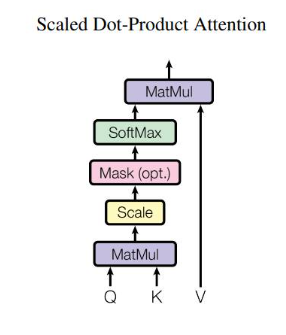


In [2]:
import torch
import torch.nn as nn
import math

class ScaledDotProductAttention(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, Q, K, V, mask=None):
        #q, k, v的shape?
        d_k = Q.size(-1) # dim

        # attention计算公式？
        K.transpose(-2, -1)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)
        
        # 掩码操作
        if mask is not None:
            scores = scores.masked_fill(mask==0, -1e9)
        
        attn = torch.softmax(scores, dim=-1) # 这个dim=-1至关重要
        output = torch.matmul(attn, V)

        return output, attn

### 2，Multi-Head Attention，多头注意力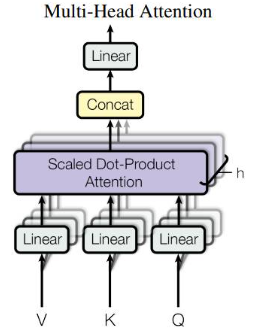

In [24]:
class MutiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0 # 相当于catch errors
        
        self.d_model = d_model 
        self.n_heads = n_heads # 定义多少个头
        self.d_k = d_model // n_heads # 进行切片，每个片过不同的头，从而计算不同的attention
        
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.fc = nn.Linear(d_model, d_model)

        self.attn = ScaledDotProductAttention()

    def forward(self, q, k, v, mask=None):
        B, L, _ = q.size()
        
        Q = self.W_q(q)
        K = self.W_k(k)
        V = self.W_v(v)

        # 分别分头处理, 转置方便进行注意力计算
        Q = Q.view(B, L, self.n_heads, self.d_k).transpose(1, 2)  
        K = K.view(B, L, self.n_heads, self.d_k).transpose(1, 2)
        V = V.view(B, L, self.n_heads, self.d_k).transpose(1, 2)

        out, attn = self.attn(Q, K, V, mask)

        # 拼接头
        out = out.transpose(1, 2).contiguous() # contiguous保证张量连续
        out = out.view(B, L, self.d_model) # 重新塑形

        return self.fc(out) # 过一个全连接让其信息融合



### 3，Feed Forward Network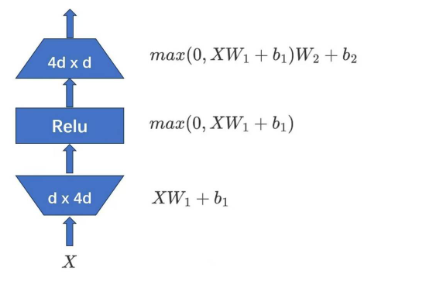

In [4]:
class FeedForward(nn.Module):
    def __init__(self, d_model, d_ffn):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ffn),
            nn.ReLU(),
            nn.Linear(d_ffn, d_model),
            nn.ReLU()
            # 这里 是否还需要一个Relu------------------------------------????
        )    
    def forward(self, x):
        return self.net(x)

### 4, Layernorm-层归一化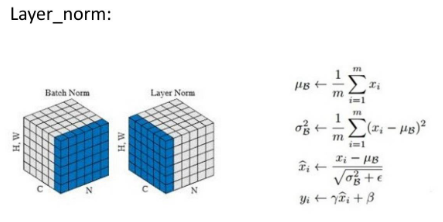

In [5]:
class LayerNorm(nn.Module):
    def __init__(self, d_model, eps=1e-12):
        super(LayerNorm, self).__init__()
        self.gamma = nn.Parameter(torch.ones(d_model))
        self.beta = nn.Parameter(torch.zeros(d_model))
        self.eps = eps

    def forward(self, x):
        mean = x.mean(-1, keepdim=True) # 求均值
        var = x.var(-1, unbiased=False, keepdim=True) # 平方
        out = (x - mean) / torch.sqrt(var + 1e-9) # 计算xi
        out = self.gamma * out + self.beta
        return out

### 5, 组装encoder block和decoder block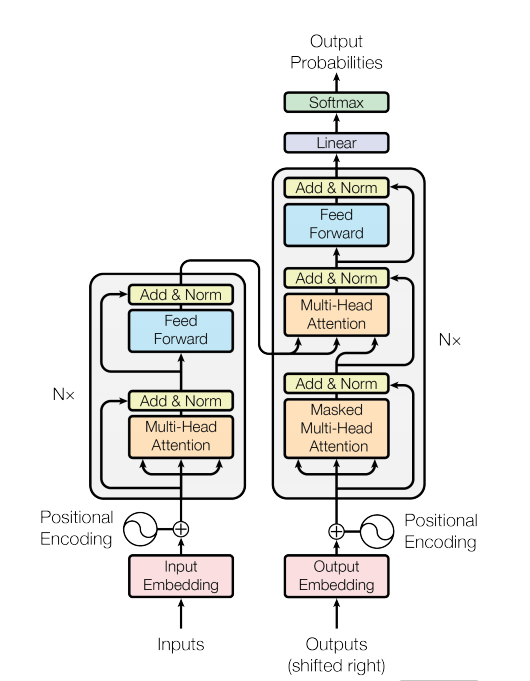

In [6]:
class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ffn):
        super().__init__()
        self.self_attn = MutiHeadAttention(d_model, n_heads)
        self.ffn = FeedForward(d_model, d_ffn)

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x, src_mask):
        x = self.norm1(x + self.self_attn(x, x, x, src_mask))
        x = self.norm2(x + self.ffn(x))
        return x
    
class DecoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ffn):
        super().__init__()
        self.self_attn = MutiHeadAttention(d_model, n_heads)
        self.enc_attn = MutiHeadAttention(d_model, n_heads)
        self.ffn = FeedForward(d_model, d_ffn)

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)

    def forward(self, x, enc_out, tgt_mask, src_mask):
        # 在此之前已经默认x就是经过Positional encoding的x了

        # 1，掩码多头注意力
        x = self.norm1(x + self.self_attn(x, x, x, tgt_mask))
        # 2，cross——attention
        x = self.norm2(x + self.enc_attn(x, enc_out, enc_out)) # 注意decoder中的x充当crossattention的第一个参数
        # 3，前馈神经网络
        x = self.norm3(x + self.ffn(x))
        
        return x
    

### 6， Postional Coding位置编码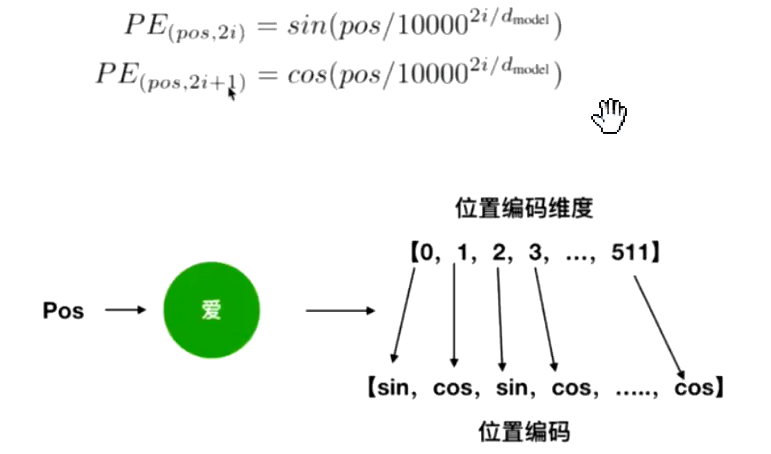

In [7]:
# 不用实现，知道位置编码是干什么的即可
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        # x:[batch,len,dim]
        pe = torch.zeros(max_len, d_model) #[len,dim]
        pos = torch.arange(0, max_len).unsqueeze(1)  #[len,1]
        div = torch.exp(torch.arange(0, d_model, 2) * -(math.log(10000.0) / d_model))

        pe[:, 0::2] = torch.sin(pos * div) #基数用sin
        pe[:, 1::2] = torch.cos(pos * div) #偶数用cos
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


### 7， Mask Matrix

In [19]:
class Mask_Address:
    def make_src_mask(self, src):
        return (src != 0).unsqueeze(1).unsqueeze(2)
    
    def make_tgt_mask(self, tgt):
        B, L = tgt.size()
        pad_mask = (tgt != 0).unsqueeze(1).unsqueeze(2)
        causal_mask = torch.tril(torch.ones(L, L)).to(tgt.device).bool()
        return pad_mask & causal_mask # 返回masked后的矩阵


### 8， transformer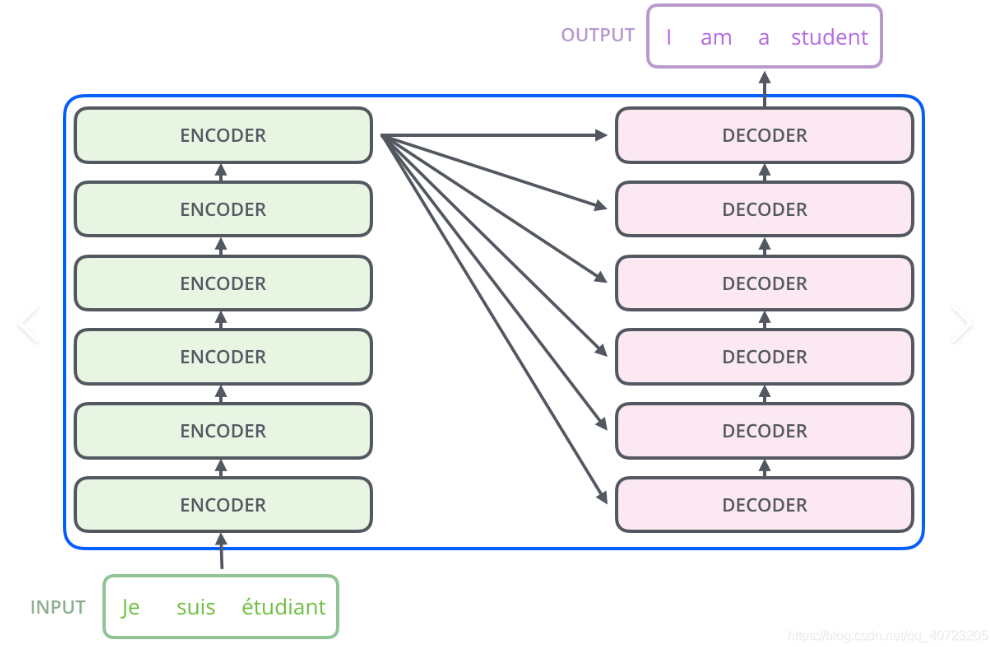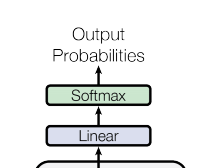

In [20]:
class Transformer(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, d_ffn, n_layers):
        super().__init__()

        self.emb = nn.Embedding(vocab_size, d_model) # 这个就是embedding矩阵，本质是一个可学习的权重矩阵parameter
        self.pos = PositionalEncoding(d_model)
        self.mask_address = Mask_Address()    

        # 组装几个encoder部分
        self.encoder = nn.ModuleList([
            EncoderLayer(d_model, n_heads, d_ffn)
            for _ in range(n_layers)
        ])

        # 组装几个decoder部分
        self.decoder = nn.ModuleList([
            DecoderLayer(d_model, n_heads, d_ffn)
            for _ in range(n_layers)
        ])

        self.fc_out = nn.Linear(d_model, vocab_size) # 为什么是这个维度，(batch, len, d_model) → (batch, len, vocab_size)每个token的概率

    def forward(self, src, tgt):
        src_mask = self.mask_address.make_src_mask(src)
        tgt_mask = self.mask_address.make_tgt_mask(tgt)

        enc = self.pos(self.emb(src)) # 这一步就是查词表，找对应的embedding，从另一个角度看就是升维
        for layer in self.encoder:
            enc = layer(enc, src_mask) # 为什么这一步只传了两个参数，下面同理，为什么传了四个

        dec = self.pos(self.emb(tgt))
        for layer in self.decoder:
            dec = layer(dec, enc, tgt_mask, src_mask)

        return self.fc_out(dec)


        


### 9，训练

In [25]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. 固定随机种子（可复现）
torch.manual_seed(0)

# 2. 超参数
vocab_size = 20
pad_idx = 0
batch_size = 3
max_len = 7

# 3. 构造真实输入
src = torch.tensor([
    [4,  7,  9,  3, 12,  6,  0],
    [5, 11,  2, 18,  0,  0,  0],
    [8, 14,  1, 10, 13,  6,  9]
])  # [3, 7]

# 4. 构造「真实监督标签」
# 规则： y = (x % 19) + 1, padding 保持 0
tgt = torch.tensor([
    [5,  8, 10,  4, 13,  7,  0],
    [6, 12,  3, 19,  0,  0,  0],
    [9, 15,  2, 11, 14,  7, 10]
])  # [3, 7]

# 5. 初始化模型
model = Transformer(
    vocab_size=vocab_size,
    d_model=32,
    n_heads=4,
    d_ffn=64,
    n_layers=2
)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss(ignore_index=pad_idx)


num_steps = 2000
for step in range(num_steps):
    optimizer.zero_grad()
    out = model(src, tgt)
    loss = criterion(
        out.reshape(-1, vocab_size),
        tgt.reshape(-1)
    )

    loss.backward()
    optimizer.step()

    if step % 50 == 0:
        print(f"step {step:03d} | loss = {loss.item():.4f}")

# ======================
# 8. 训练后验证预测结果
# ======================
with torch.no_grad():
    logits = model(src, tgt)
    preds = logits.argmax(dim=-1)

print("\n===== Input (src) =====")
print(src)

print("\n===== Target (tgt) =====")
print(tgt)

print("\n===== Prediction =====")
print(preds)


step 000 | loss = 3.2525
step 050 | loss = 0.3904
step 100 | loss = 0.1136
step 150 | loss = 0.0590
step 200 | loss = 0.0366
step 250 | loss = 0.0251
step 300 | loss = 0.0184
step 350 | loss = 0.0140
step 400 | loss = 0.0111
step 450 | loss = 0.0090
step 500 | loss = 0.0075
step 550 | loss = 0.0063
step 600 | loss = 0.0054
step 650 | loss = 0.0046
step 700 | loss = 0.0041
step 750 | loss = 0.0036
step 800 | loss = 0.0032
step 850 | loss = 0.0028
step 900 | loss = 0.0025
step 950 | loss = 0.0023
step 1000 | loss = 0.0021
step 1050 | loss = 0.0019
step 1100 | loss = 0.0017
step 1150 | loss = 0.0016
step 1200 | loss = 0.0015
step 1250 | loss = 0.0014
step 1300 | loss = 0.0013
step 1350 | loss = 0.0012
step 1400 | loss = 0.0011
step 1450 | loss = 0.0010
step 1500 | loss = 0.0009
step 1550 | loss = 0.0009
step 1600 | loss = 0.0008
step 1650 | loss = 0.0008
step 1700 | loss = 0.0007
step 1750 | loss = 0.0007
step 1800 | loss = 0.0006
step 1850 | loss = 0.0006
step 1900 | loss = 0.0006
step 1